# WIX3001 Soft Computing
## Lab 1: Introduction to Soft Computing with Python (Basic)

**Learning objectives (CLO1, C2):** describe soft computing techniques and see how they work in code.

By the end of this lab you will be able to:
1. Use NumPy and Matplotlib for basic numerical work and plotting.
2. Implement and plot common neural network activation functions.
3. Build a simple artificial neuron (McCulloch-Pitts) and a Perceptron that learns from data.
4. Define fuzzy membership functions and perform a small fuzzy inference.
5. Run a tiny Genetic Algorithm to optimise a function.

**How to run in Google Colab:** open this file in Colab, then use Runtime > Run all (or press Shift+Enter cell by cell). No extra installation is needed.

## Part 1: Setup and Python basics

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

# Arrays and vector operations
a = np.array([1, 2, 3, 4])
b = np.array([10, 20, 30, 40])
print("a + b      =", a + b)
print("a * b      =", a * b)            # element-wise
print("dot(a, b)  =", np.dot(a, b))     # weighted sum, the core of a neuron
print("mean(a)    =", a.mean())

NumPy version: 1.26.4
a + b      = [11 22 33 44]
a * b      = [ 10  40  90 160]
dot(a, b)  = 300
mean(a)    = 2.5


## Part 2: Activation functions (Neural Networks)
Activation functions decide how a neuron responds to its weighted input.

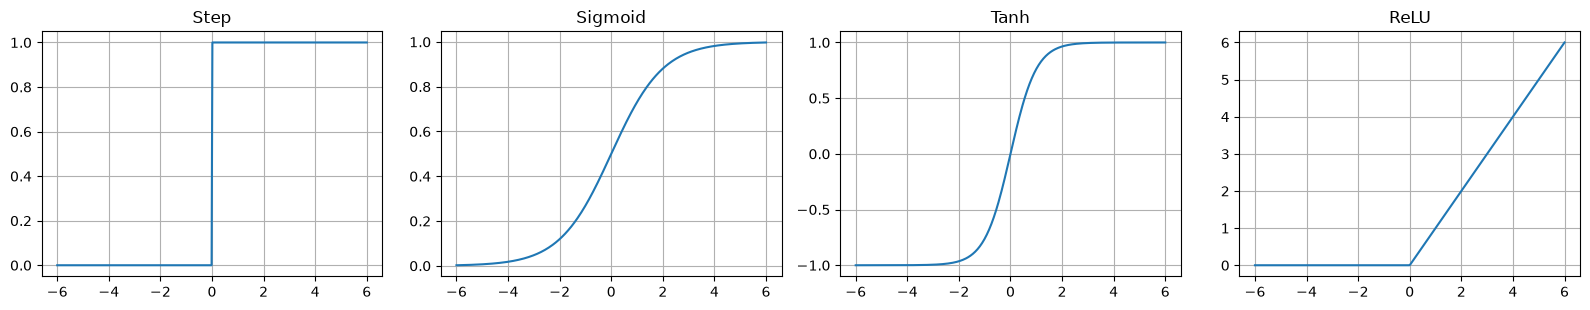

In [2]:
def step(x):      return np.where(x >= 0, 1, 0)
def sigmoid(x):   return 1 / (1 + np.exp(-x))
def tanh(x):      return np.tanh(x)
def relu(x):      return np.maximum(0, x)

x = np.linspace(-6, 6, 400)
funcs = {"Step": step, "Sigmoid": sigmoid, "Tanh": tanh, "ReLU": relu}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (name, f) in zip(axes, funcs.items()):
    ax.plot(x, f(x))
    ax.set_title(name)
    ax.grid(True)
plt.tight_layout()
plt.show()

## Part 3: A single artificial neuron (McCulloch-Pitts)
A neuron computes `y = f(w1*x1 + w2*x2 + ... + b)`. With hand-picked weights it can act as a logic gate.

In [3]:
def neuron(x, w, b):
    return step(np.dot(x, w) + b)

inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

# AND gate: fires only when both inputs are 1
w_and, b_and = np.array([1, 1]), -1.5
# OR gate: fires when at least one input is 1
w_or,  b_or  = np.array([1, 1]), -0.5

print("x1 x2 | AND OR")
for x in inputs:
    print(f" {x[0]}  {x[1]} |  {neuron(x, w_and, b_and)}   {neuron(x, w_or, b_or)}")

x1 x2 | AND OR
 0  0 |  0   0
 0  1 |  0   1
 1  0 |  0   1
 1  1 |  1   1


## Part 4: The Perceptron learns from data
Instead of choosing weights by hand, the Perceptron learning rule adjusts them:

`w = w + lr * (target - prediction) * x`

Learned weights: [0.2 0.1]  bias: -0.20000000000000004
Predictions: [0 0 0 1]  Targets: [0 0 0 1]


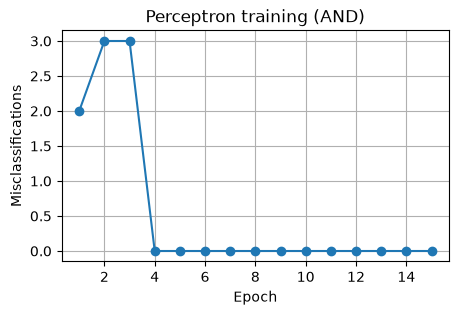

In [4]:
class Perceptron:
    def __init__(self, n_inputs, lr=0.1, epochs=20):
        self.w = np.zeros(n_inputs)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.errors_per_epoch = []

    def predict(self, X):
        return step(np.dot(X, self.w) + self.b)

    def fit(self, X, y):
        for _ in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                pred = self.predict(xi)
                update = self.lr * (target - pred)
                self.w += update * xi
                self.b += update
                errors += int(update != 0)
            self.errors_per_epoch.append(errors)
        return self

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

p = Perceptron(n_inputs=2, lr=0.1, epochs=15).fit(X, y_and)
print("Learned weights:", p.w, " bias:", p.b)
print("Predictions:", p.predict(X), " Targets:", y_and)

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(p.errors_per_epoch) + 1), p.errors_per_epoch, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Misclassifications"); plt.title("Perceptron training (AND)")
plt.grid(True); plt.show()

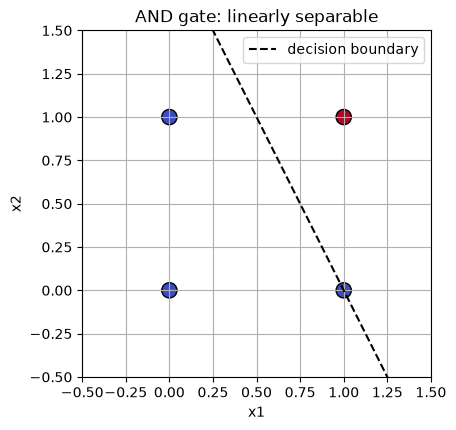

In [5]:
# Decision boundary of the learned AND gate
xx = np.linspace(-0.5, 1.5, 100)
yy = -(p.w[0] * xx + p.b) / p.w[1]

plt.figure(figsize=(4.5, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y_and, cmap="coolwarm", s=120, edgecolors="k")
plt.plot(xx, yy, "k--", label="decision boundary")
plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5)
plt.xlabel("x1"); plt.ylabel("x2"); plt.legend(); plt.grid(True)
plt.title("AND gate: linearly separable")
plt.show()

# Question: what happens if you train on XOR, y = [0, 1, 1, 0]? Try it in the exercises.

## Part 5: Fuzzy logic basics
Fuzzy sets allow **degrees of membership** between 0 and 1 instead of strict true/false.
Here we model room temperature as *Cold*, *Warm* and *Hot*.

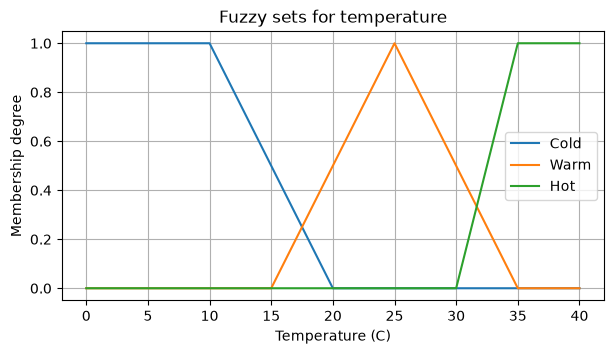

At 28 C -> Cold=0.00, Warm=0.70, Hot=0.00


In [6]:
def trimf(x, a, b, c):
    """Triangular membership function with feet at a and c and peak at b."""
    x = np.asarray(x, dtype=float)
    left  = (x - a) / (b - a)
    right = (c - x) / (c - b)
    return np.clip(np.minimum(left, right), 0, 1)

def trapmf(x, a, b, c, d):
    """Trapezoidal membership function."""
    x = np.asarray(x, dtype=float)
    left  = (x - a) / (b - a) if b != a else np.ones_like(x)
    right = (d - x) / (d - c) if d != c else np.ones_like(x)
    return np.clip(np.minimum(np.minimum(left, 1), right), 0, 1)

temp = np.linspace(0, 40, 401)
cold = trapmf(temp, -1, 0, 10, 20)
warm = trimf(temp, 15, 25, 35)
hot  = trapmf(temp, 30, 35, 40, 41)

plt.figure(figsize=(7, 3.5))
plt.plot(temp, cold, label="Cold")
plt.plot(temp, warm, label="Warm")
plt.plot(temp, hot,  label="Hot")
plt.xlabel("Temperature (C)"); plt.ylabel("Membership degree")
plt.title("Fuzzy sets for temperature"); plt.legend(); plt.grid(True)
plt.show()

# Fuzzification of one crisp reading
t = 28
print(f"At {t} C -> Cold={trapmf(t,-1,0,10,20):.2f}, Warm={trimf(t,15,25,35):.2f}, Hot={trapmf(t,30,35,40,41):.2f}")

### Mini fuzzy inference (fan speed)
Rules:
- IF temperature is Cold THEN fan is Slow
- IF temperature is Warm THEN fan is Medium
- IF temperature is Hot THEN fan is Fast

We use min-clipping, max aggregation and centroid defuzzification (Mamdani style).

Temperature  5 C -> fan speed  16.6 %
Temperature 18 C -> fan speed  39.0 %
Temperature 25 C -> fan speed  50.0 %
Temperature 28 C -> fan speed  50.0 %
Temperature 33 C -> fan speed  73.2 %
Temperature 38 C -> fan speed  83.4 %


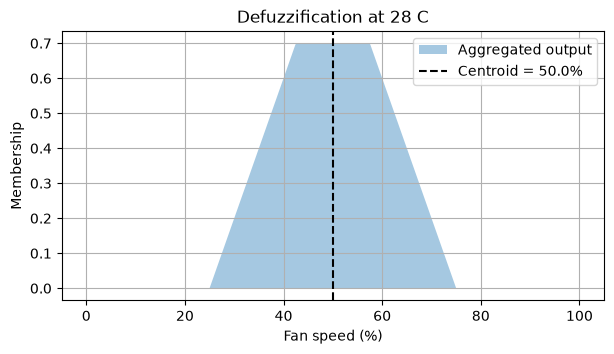

In [7]:
fan = np.linspace(0, 100, 501)           # fan speed in percent
slow   = trimf(fan, -1, 0, 50)
medium = trimf(fan, 25, 50, 75)
fast   = trimf(fan, 50, 100, 101)

def fan_speed(t):
    mu_cold = float(trapmf(t, -1, 0, 10, 20))
    mu_warm = float(trimf(t, 15, 25, 35))
    mu_hot  = float(trapmf(t, 30, 35, 40, 41))

    clipped = np.maximum.reduce([
        np.minimum(mu_cold, slow),
        np.minimum(mu_warm, medium),
        np.minimum(mu_hot,  fast),
    ])
    if clipped.sum() == 0:
        return 0.0, clipped
    return float((fan * clipped).sum() / clipped.sum()), clipped   # centroid

for t in [5, 18, 25, 28, 33, 38]:
    print(f"Temperature {t:>2} C -> fan speed {fan_speed(t)[0]:5.1f} %")

speed, agg = fan_speed(28)
plt.figure(figsize=(7, 3.5))
plt.fill_between(fan, agg, alpha=0.4, label="Aggregated output")
plt.axvline(speed, color="k", linestyle="--", label=f"Centroid = {speed:.1f}%")
plt.xlabel("Fan speed (%)"); plt.ylabel("Membership"); plt.title("Defuzzification at 28 C")
plt.legend(); plt.grid(True); plt.show()

## Part 6: A tiny Genetic Algorithm (Evolutionary Computation)
Goal: find the integer `x` in [0, 31] that maximises `f(x) = x * (31 - x)`, whose maximum is at x = 15 or 16.

Steps: encode as 5-bit binary, select parents, crossover, mutate, repeat.

Best x: 15  fitness: 240


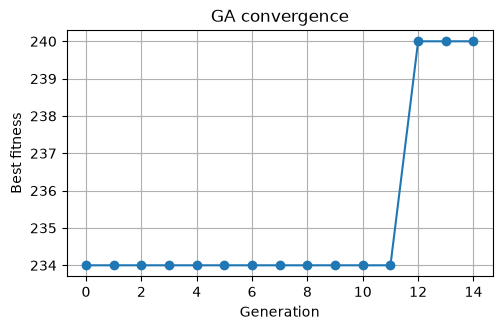

In [8]:
rng = np.random.default_rng(42)

def decode(bits):  return int("".join(map(str, bits)), 2)
def fitness(bits):
    x = decode(bits)
    return x * (31 - x)

POP, GENS, PC, PM = 8, 15, 0.9, 0.05
pop = rng.integers(0, 2, size=(POP, 5))
best_history = []

for g in range(GENS):
    fits = np.array([fitness(ind) for ind in pop])
    best_history.append(fits.max())

    # Roulette wheel selection
    probs = (fits + 1e-9) / (fits + 1e-9).sum()
    parents = pop[rng.choice(POP, size=POP, p=probs)]

    # Single-point crossover
    children = parents.copy()
    for i in range(0, POP - 1, 2):
        if rng.random() < PC:
            cut = rng.integers(1, 5)
            children[i, cut:], children[i + 1, cut:] = parents[i + 1, cut:].copy(), parents[i, cut:].copy()

    # Bit-flip mutation
    mask = rng.random(children.shape) < PM
    children = np.where(mask, 1 - children, children)

    # Elitism: keep the best individual from the previous generation
    children[0] = pop[fits.argmax()]
    pop = children

fits = np.array([fitness(ind) for ind in pop])
best = pop[fits.argmax()]
print("Best x:", decode(best), " fitness:", fitness(best))

plt.figure(figsize=(5.5, 3.2))
plt.plot(best_history, marker="o")
plt.xlabel("Generation"); plt.ylabel("Best fitness"); plt.title("GA convergence")
plt.grid(True); plt.show()

## Part 7: Exercises (submit in your lab report)
1. **Activation functions:** add the Leaky ReLU `f(x) = max(0.01x, x)` and plot it next to ReLU.
2. **Logic gates:** find weights and a bias for a NAND gate and a NOR gate, then verify with the truth table.
3. **Perceptron:** train the Perceptron on OR, then on XOR (`[0, 1, 1, 0]`). Explain why XOR fails.
4. **Fuzzy:** add a fourth fuzzy set, *Very Hot* (above 35 C), and a rule that sets fan speed to *Fast*. Compare the output at 38 C.
5. **Genetic Algorithm:** change population size, crossover rate and mutation rate. Report how each affects convergence.
6. **Reflection (3 to 5 sentences):** compare neural, fuzzy and evolutionary approaches. Which would you use for (a) image recognition, (b) a washing machine controller, (c) route optimisation, and why?

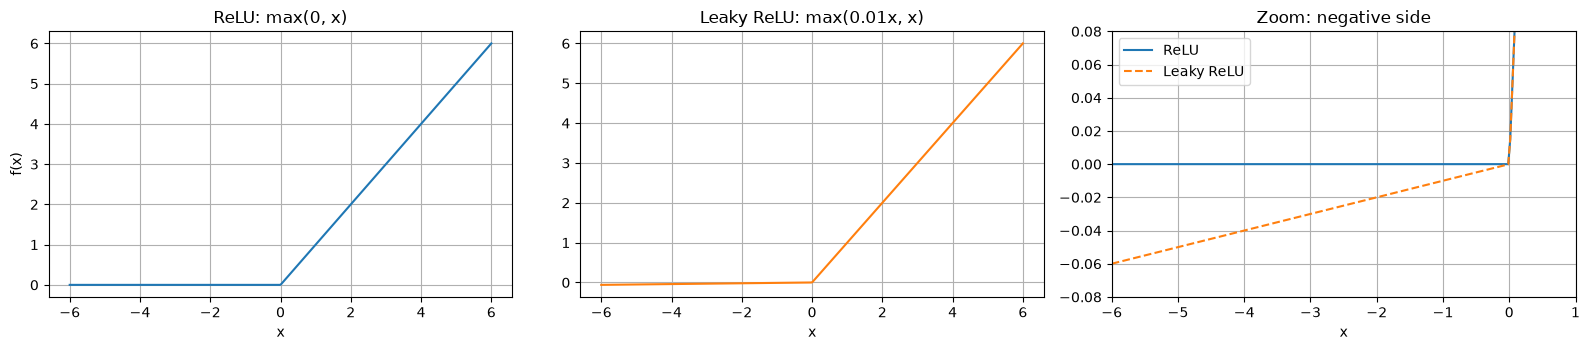

    x |  ReLU | Leaky ReLU
   -6 |  0.00 |    -0.060
   -2 |  0.00 |    -0.020
 -0.5 |  0.00 |    -0.005
    0 |  0.00 |     0.000
  0.5 |  0.50 |     0.500
    2 |  2.00 |     2.000
    6 |  6.00 |     6.000


In [14]:
# =====================================================================
# Exercise 1: Leaky ReLU vs ReLU
# =====================================================================
def leaky_relu(x, alpha=0.01):
    """Leaky ReLU: f(x) = max(alpha*x, x).
    For x >= 0 it returns x (same as ReLU).
    For x <  0 it returns alpha*x, a small negative value instead of 0,
    so the neuron never becomes completely 'dead'."""
    return np.maximum(alpha * x, x)

x = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))

# (a) ReLU on its own
axes[0].plot(x, relu(x))
axes[0].set_title("ReLU: max(0, x)")

# (b) Leaky ReLU on its own
axes[1].plot(x, leaky_relu(x), color="tab:orange")
axes[1].set_title("Leaky ReLU: max(0.01x, x)")

# (c) Both together, zoomed in on x < 0 so the small slope is visible
axes[2].plot(x, relu(x), label="ReLU")
axes[2].plot(x, leaky_relu(x), "--", label="Leaky ReLU")
axes[2].set_xlim(-6, 1)
axes[2].set_ylim(-0.08, 0.08)
axes[2].set_title("Zoom: negative side")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("x")
    ax.grid(True)
axes[0].set_ylabel("f(x)")
plt.tight_layout()
plt.show()

# Numerical comparison at a few points
print("    x |  ReLU | Leaky ReLU")
for v in [-6, -2, -0.5, 0, 0.5, 2, 6]:
    print(f"{v:5} | {float(relu(v)):5.2f} | {float(leaky_relu(v)):9.3f}")

**Observation.** For x ≥ 0 the two functions are identical (f(x) = x). For x < 0, ReLU always outputs 0, so its slope is 0 and a neuron stuck in that region stops learning (the "dying ReLU" problem). Leaky ReLU outputs 0.01x instead (for example −0.06 at x = −6), so it keeps a small slope of 0.01 and the neuron can still recover during training. The difference is too small to see at full scale, which is why the third plot zooms in on the negative side.

In [15]:
# =====================================================================
# Exercise 2: NAND and NOR gates with a single neuron
# =====================================================================
# Idea: NAND = NOT(AND) and NOR = NOT(OR).
# Flipping the sign of every weight AND the bias flips the sign of z,
# so the neuron fires in exactly the opposite cases.
w_nand, b_nand = np.array([-1, -1]),  1.5   # = -(AND weights), -(AND bias)
w_nor,  b_nor  = np.array([-1, -1]),  0.5   # = -(OR weights),  -(OR bias)

expected_nand = [1, 1, 1, 0]   # 0 only when both inputs are 1
expected_nor  = [1, 0, 0, 0]   # 1 only when both inputs are 0

print("x1 x2 | z_NAND NAND | z_NOR NOR")
for x_in, e_nand, e_nor in zip(inputs, expected_nand, expected_nor):
    z_nand = np.dot(x_in, w_nand) + b_nand
    z_nor  = np.dot(x_in, w_nor)  + b_nor
    out_nand = int(neuron(x_in, w_nand, b_nand))
    out_nor  = int(neuron(x_in, w_nor,  b_nor))
    print(f" {x_in[0]}  {x_in[1]} |  {z_nand:5.1f}   {out_nand}  |  {z_nor:4.1f}   {out_nor}")
    # Verification: stop with an error if any row is wrong
    assert out_nand == e_nand, f"NAND wrong for {x_in}"
    assert out_nor  == e_nor,  f"NOR wrong for {x_in}"

print("\nAll rows match the NAND and NOR truth tables.")

x1 x2 | z_NAND NAND | z_NOR NOR
 0  0 |    1.5   1  |   0.5   1
 0  1 |    0.5   1  |  -0.5   0
 1  0 |    0.5   1  |  -0.5   0
 1  1 |   -0.5   0  |  -1.5   0

All rows match the NAND and NOR truth tables.


**Answer.**

| Gate | w1 | w2 | b | Fires when |
|---|---|---|---|---|
| NAND | −1 | −1 | 1.5 | x1 + x2 ≤ 1.5 |
| NOR | −1 | −1 | 0.5 | x1 + x2 ≤ 0.5 |

NAND = NOT(AND) and NOR = NOT(OR). Multiplying every weight and the bias of the AND/OR neuron by −1 flips the sign of z, so the neuron fires in exactly the opposite cases. This works because z is never exactly 0 for any of the four inputs; if it were, `step(0) = 1` would make both the gate and its negation fire.

OR
  Learned weights: [0.1 0.1]  bias: -0.1
  Predictions: [0 1 1 1]  Targets: [0 1 1 1]
  Errors per epoch: [2, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

XOR
  Learned weights: [-0.1  0. ]  bias: 0.0
  Predictions: [1 1 0 0]  Targets: [0 1 1 0]
  Accuracy: 0.5
  Errors per epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


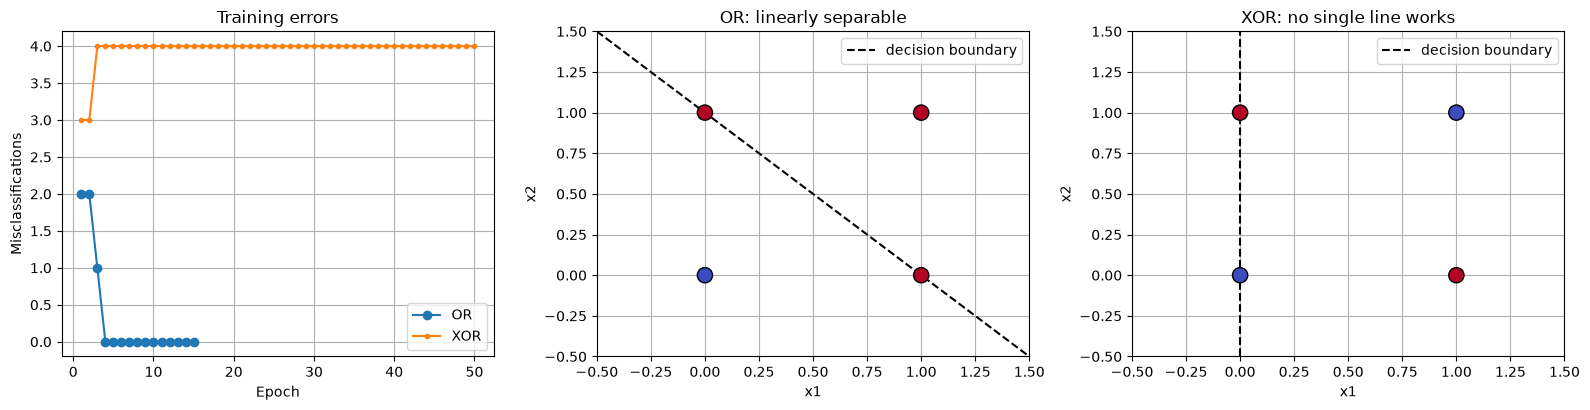

In [16]:
# =====================================================================
# Exercise 3: Perceptron on OR, then on XOR
# =====================================================================
y_or  = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

def plot_boundary(ax, model, X, y, title):
    """Scatter the 4 points (blue = 0, red = 1) and draw the line w1*x1 + w2*x2 + b = 0."""
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=120, edgecolors="k", zorder=3)
    w1, w2, b = model.w[0], model.w[1], model.b
    xx = np.linspace(-0.5, 1.5, 100)
    if abs(w2) > 1e-12:                       # normal case: solve for x2
        ax.plot(xx, -(w1 * xx + b) / w2, "k--", label="decision boundary")
    elif abs(w1) > 1e-12:                     # w2 = 0 -> vertical line x1 = -b/w1
        ax.axvline(-b / w1, color="k", linestyle="--", label="decision boundary")
    else:                                     # w1 = w2 = 0 -> no line exists
        ax.text(0.5, 1.3, "no boundary (w = 0)", ha="center")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.grid(True); ax.set_title(title)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="upper right")

# --- OR: linearly separable, should converge ---
p_or = Perceptron(n_inputs=2, lr=0.1, epochs=15).fit(X, y_or)
print("OR")
print("  Learned weights:", p_or.w, " bias:", p_or.b)
print("  Predictions:", p_or.predict(X), " Targets:", y_or)
print("  Errors per epoch:", p_or.errors_per_epoch)

# --- XOR: not linearly separable, will never converge ---
p_xor = Perceptron(n_inputs=2, lr=0.1, epochs=50).fit(X, y_xor)
xor_pred = p_xor.predict(X)
print("\nXOR")
print("  Learned weights:", p_xor.w, " bias:", p_xor.b)
print("  Predictions:", xor_pred, " Targets:", y_xor)
print("  Accuracy:", (xor_pred == y_xor).mean())
print("  Errors per epoch:", p_xor.errors_per_epoch)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(range(1, len(p_or.errors_per_epoch) + 1), p_or.errors_per_epoch, marker="o", label="OR")
axes[0].plot(range(1, len(p_xor.errors_per_epoch) + 1), p_xor.errors_per_epoch, marker=".", label="XOR")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Misclassifications")
axes[0].set_title("Training errors"); axes[0].grid(True); axes[0].legend()
plot_boundary(axes[1], p_or,  X, y_or,  "OR: linearly separable")
plot_boundary(axes[2], p_xor, X, y_xor, "XOR: no single line works")
plt.tight_layout(); plt.show()

In [17]:
# Proof that XOR CAN be solved once we add a hidden layer:
# XOR(x1, x2) = AND( OR(x1, x2), NAND(x1, x2) )
def xor_two_layer(x_in):
    h1 = neuron(x_in, w_or,   b_or)     # hidden neuron 1: OR
    h2 = neuron(x_in, w_nand, b_nand)   # hidden neuron 2: NAND
    return neuron(np.array([h1, h2]), w_and, b_and)   # output neuron: AND

print("x1 x2 | OR NAND | XOR")
for x_in, target in zip(inputs, y_xor):
    h1 = int(neuron(x_in, w_or, b_or))
    h2 = int(neuron(x_in, w_nand, b_nand))
    out = int(xor_two_layer(x_in))
    print(f" {x_in[0]}  {x_in[1]} |  {h1}   {h2}  |  {out}")
    assert out == target
print("\nThe 2-layer network reproduces XOR exactly.")

x1 x2 | OR NAND | XOR
 0  0 |  0   1  |  0
 0  1 |  1   1  |  1
 1  0 |  1   1  |  1
 1  1 |  1   0  |  0

The 2-layer network reproduces XOR exactly.


**OR** is learned in 3 epochs (errors 2, 2, 1, then 0), giving w = [0.1, 0.1] and b = −0.1. The boundary is the line x1 + x2 = 1, which separates (0,0) from the other three points. (0,1) and (1,0) lie exactly on the line, where z = 0 and `step(0) = 1`, so they are still classified as 1.

**XOR** never converges. After 50 epochs it still makes 4 mistakes per epoch, the accuracy of the final weights is only 50 %, and the predictions are [1, 1, 0, 0] instead of [0, 1, 1, 0].

**Why XOR fails.** A single perceptron can only draw one straight line, and XOR's two classes sit on opposite corners of the square, so no line separates them: XOR is **not linearly separable**. Algebraically, XOR would need
(0,0): b < 0, (0,1): w2 + b ≥ 0, (1,0): w1 + b ≥ 0, (1,1): w1 + w2 + b < 0.
Adding the middle two gives w1 + w2 + 2b ≥ 0, so w1 + w2 + b ≥ −b > 0, which contradicts the last condition. No weights exist, so the learning rule keeps correcting forever.

**Fix.** Add a hidden layer: XOR = AND(OR, NAND). The second cell builds this 2-layer network from the gates in Exercise 2 and reproduces XOR exactly. This is why multi-layer networks are needed.

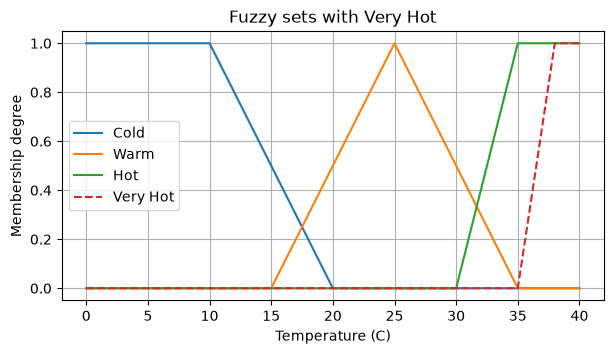

 Temp |  Hot  VeryHot | 3 rules | 4 rules
  30C | 0.00   0.00  |   50.0% |   50.0%
  33C | 0.60   0.00  |   73.2% |   73.2%
  35C | 1.00   0.00  |   83.4% |   83.4%
  36C | 1.00   0.33  |   83.4% |   83.4%
  38C | 1.00   1.00  |   83.4% |   83.4%
  40C | 1.00   1.00  |   83.4% |   83.4%

At 38 C: 3 rules -> 83.4%, 4 rules -> 83.4%
Aggregated shapes identical at 38 C: True


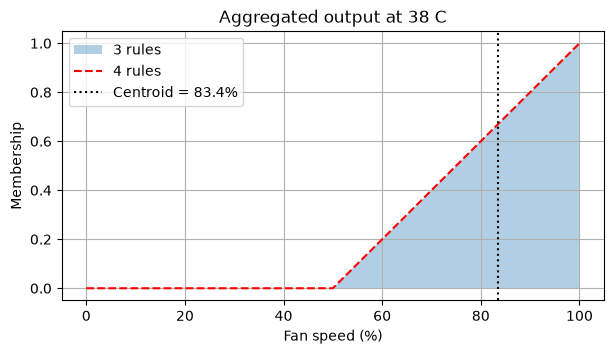

In [18]:
# =====================================================================
# Exercise 4: add a 4th fuzzy set "Very Hot" (above 35 C) -> fan Fast
# =====================================================================
# Design choice: Very Hot starts at 35 C, is fully true from 38 C,
# and uses the same 40/41 "shoulder" trick as Hot so it stays at 1 up to 40 C.
VH = (35, 38, 40, 41)
very_hot = trapmf(temp, *VH)

# Membership functions as small helpers (crisp temperature -> degree)
mu_cold     = lambda t: float(trapmf(t, -1, 0, 10, 20))
mu_warm     = lambda t: float(trimf(t, 15, 25, 35))
mu_hot      = lambda t: float(trapmf(t, 30, 35, 40, 41))
mu_very_hot = lambda t: float(trapmf(t, *VH))

def mamdani(t, rules):
    """General Mamdani inference.
    rules = list of (membership_function, output_set) pairs.
    1) fuzzify  2) min-clip each output set  3) max-aggregate  4) centroid."""
    clipped = np.maximum.reduce([np.minimum(mu(t), out_set) for mu, out_set in rules])
    if clipped.sum() == 0:
        return 0.0, clipped
    return float((fan * clipped).sum() / clipped.sum()), clipped

rules_3 = [(mu_cold, slow), (mu_warm, medium), (mu_hot, fast)]
rules_4 = rules_3 + [(mu_very_hot, fast)]          # NEW: IF Very Hot THEN Fast

# Sanity check: the 3-rule version must reproduce Part 5 exactly
for t in [5, 18, 25, 28, 33, 38]:
    assert abs(mamdani(t, rules_3)[0] - fan_speed(t)[0]) < 1e-9

# --- Plot the four temperature sets ---
plt.figure(figsize=(7, 3.5))
plt.plot(temp, cold, label="Cold")
plt.plot(temp, warm, label="Warm")
plt.plot(temp, hot,  label="Hot")
plt.plot(temp, very_hot, "--", label="Very Hot")
plt.xlabel("Temperature (C)"); plt.ylabel("Membership degree")
plt.title("Fuzzy sets with Very Hot"); plt.legend(); plt.grid(True)
plt.show()

# --- Compare 3 rules vs 4 rules ---
print(" Temp |  Hot  VeryHot | 3 rules | 4 rules")
for t in [30, 33, 35, 36, 38, 40]:
    s3 = mamdani(t, rules_3)[0]
    s4 = mamdani(t, rules_4)[0]
    print(f" {t:>3}C | {mu_hot(t):4.2f}   {mu_very_hot(t):4.2f}  | {s3:6.1f}% | {s4:6.1f}%")

s3_38, agg3 = mamdani(38, rules_3)
s4_38, agg4 = mamdani(38, rules_4)
print(f"\nAt 38 C: 3 rules -> {s3_38:.1f}%, 4 rules -> {s4_38:.1f}%")
print("Aggregated shapes identical at 38 C:", np.allclose(agg3, agg4))

plt.figure(figsize=(7, 3.5))
plt.fill_between(fan, agg3, alpha=0.35, label="3 rules")
plt.plot(fan, agg4, "r--", label="4 rules")
plt.axvline(s4_38, color="k", linestyle=":", label=f"Centroid = {s4_38:.1f}%")
plt.xlabel("Fan speed (%)"); plt.ylabel("Membership"); plt.title("Aggregated output at 38 C")
plt.legend(); plt.grid(True); plt.show()

Very Hot is a trapezoid with feet/shoulders (35, 38, 40, 41): 0 at 35 °C, rising to 1 at 38 °C, staying at 1 up to 40 °C. New rule: **IF temperature is Very Hot THEN fan is Fast.**

**Result.** At 38 °C the fan speed is **83.4 % with both 3 rules and 4 rules**. The aggregated output shapes are identical; in fact the outputs are identical at every temperature from 0 to 40 °C.

**Why nothing changes.**
1. Wherever Very Hot is above 0 (35–40 °C), Hot is already fully 1.
2. Both rules point to the same output set, Fast. At 38 °C both clip Fast at height 1, so each gives the whole Fast triangle.
3. Max aggregation keeps the larger of two identical shapes, which is the same shape, so the centroid does not move.

The new rule is **redundant**. For Very Hot to raise the fan speed, it would need its own output set further to the right (e.g. *Very Fast*) and Hot would need to fade out above 35 °C so the two rules compete. The table also shows that this design can never exceed 83.4 %, because that is the centroid of the Fast triangle (50, 100, 100).


Population size (others fixed at POP=8, PC=0.9, PM=0.05)
  pop_size | success | mean gen to hit 240 | mean final best
         4 |    84%  |                4.12 |           238.8
         8 |   100%  |                2.61 |           240.0
        16 |   100%  |                0.56 |           240.0
        32 |   100%  |                0.10 |           240.0

Crossover rate (others fixed at POP=8, PC=0.9, PM=0.05)
        pc | success | mean gen to hit 240 | mean final best
       0.0 |    94%  |                3.23 |           239.9
       0.3 |    97%  |                2.53 |           239.9
       0.6 |    98%  |                1.98 |           240.0
       0.9 |   100%  |                2.61 |           240.0
       1.0 |   100%  |                1.78 |           240.0

Mutation rate (others fixed at POP=8, PC=0.9, PM=0.05)
        pm | success | mean gen to hit 240 | mean final best
       0.0 |    76%  |                1.16 |           238.6
      0.01 |    91%  |              

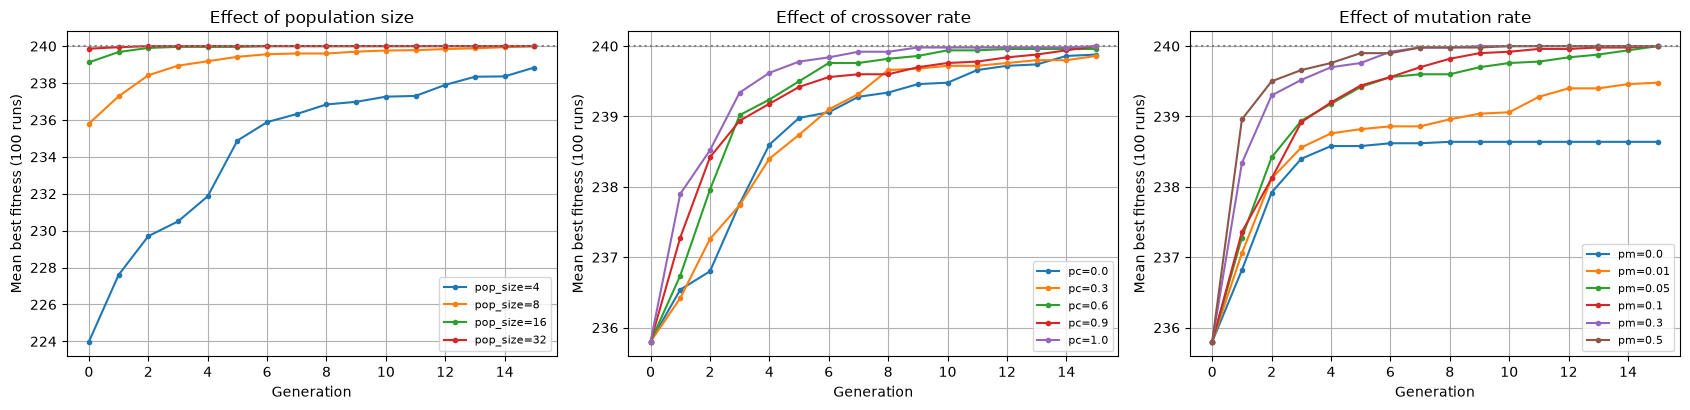

In [19]:
# =====================================================================
# Exercise 5: effect of population size, crossover rate, mutation rate
# =====================================================================
def run_ga(pop_size=8, gens=15, pc=0.9, pm=0.05, seed=42):
    """Same GA as Part 6, wrapped in a function so the settings can change.
    Returns (best fitness of each generation, best fitness of final population)."""
    rng = np.random.default_rng(seed)
    pop = rng.integers(0, 2, size=(pop_size, 5))
    history = []
    for g in range(gens):
        fits = np.array([fitness(ind) for ind in pop])
        history.append(fits.max())
        probs = (fits + 1e-9) / (fits + 1e-9).sum()
        parents = pop[rng.choice(pop_size, size=pop_size, p=probs)]
        children = parents.copy()
        for i in range(0, pop_size - 1, 2):
            if rng.random() < pc:
                cut = rng.integers(1, 5)
                children[i, cut:], children[i + 1, cut:] = parents[i + 1, cut:].copy(), parents[i, cut:].copy()
        mask = rng.random(children.shape) < pm
        children = np.where(mask, 1 - children, children)
        children[0] = pop[fits.argmax()]          # elitism
        pop = children
    final_best = max(fitness(ind) for ind in pop)
    return np.array(history), final_best

# Sanity check: default settings with seed 42 reproduce Part 6 exactly
h42, _ = run_ga(seed=42)
assert list(h42) == list(best_history), "run_ga does not match Part 6"

# One run depends heavily on luck, so every setting is run with 100 different seeds
N_RUNS, GENS_EXP = 100, 15

def experiment(**settings):
    curves, success, first_hit = [], 0, []
    for seed in range(N_RUNS):
        hist, final = run_ga(gens=GENS_EXP, seed=seed, **settings)
        full = np.append(hist, final)            # generations 0..15
        curves.append(full)
        if final == 240:
            success += 1
            first_hit.append(int(np.argmax(full == 240)))
    mean_hit = np.mean(first_hit) if first_hit else float("nan")
    return np.mean(curves, axis=0), success / N_RUNS, mean_hit

base = dict(pop_size=8, pc=0.9, pm=0.05)
grids = {
    "pop_size": [4, 8, 16, 32],
    "pc":       [0.0, 0.3, 0.6, 0.9, 1.0],
    "pm":       [0.0, 0.01, 0.05, 0.1, 0.3, 0.5],
}
labels = {"pop_size": "Population size", "pc": "Crossover rate", "pm": "Mutation rate"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (param, values) in zip(axes, grids.items()):
    print(f"\n{labels[param]} (others fixed at POP=8, PC=0.9, PM=0.05)")
    print(f"  {param:>8} | success | mean gen to hit 240 | mean final best")
    for v in values:
        settings = {**base, param: v}
        curve, rate, hit = experiment(**settings)
        print(f"  {v:>8} |  {rate:5.0%}  | {hit:19.2f} | {curve[-1]:15.1f}")
        ax.plot(range(GENS_EXP + 1), curve, marker=".", label=f"{param}={v}")
    ax.axhline(240, color="grey", linestyle=":")
    ax.set_xlabel("Generation"); ax.set_ylabel("Mean best fitness (100 runs)")
    ax.set_title(f"Effect of {labels[param].lower()}"); ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

One GA run depends heavily on the random seed, so each setting is run with 100 seeds (0–99), 15 generations, changing one parameter at a time from the default POP = 8, PC = 0.9, PM = 0.05. *Success* = the final population contains x = 15 or 16 (fitness 240). *Mean gen to hit 240* is averaged over successful runs only.

**Population size.** Larger populations converge faster and more reliably: success rises from 84 % (POP = 4) to 100 % (POP ≥ 8), and the mean generation to reach 240 drops from 4.12 to 0.10. Part of this is luck at initialisation: with only 32 possible values, a population of 32 already contains 15 or 16 in about 87 % of runs (1 − (30/32)³²). The cost is more fitness evaluations per generation (POP × 15: 60 for POP = 4, 480 for POP = 32).

**Crossover rate.** Higher crossover generally helps: success goes from 94 % (PC = 0) to 100 % (PC = 0.9 and 1.0), and mean generations fall from 3.23 to 1.78. The trend is not perfectly smooth (PC = 0.6 averaged 1.98, PC = 0.9 averaged 2.61) because of run-to-run randomness. Even with PC = 0 the GA usually succeeds, because selection plus mutation alone can find the optimum in such a small search space.

**Mutation rate.** With PM = 0 only 76 % of runs succeed: with no mutation the population cannot create bit values that were missing at the start and can converge prematurely on 234 (x = 13 or 18). The low 1.16 mean generations for PM = 0 only reflects runs that started close to the optimum. PM = 0.05 and above gave 100 % success, and higher rates were even faster here, because with only 32 candidates heavy mutation acts like random search and elitism protects the best solution. In larger problems a high mutation rate destroys good building blocks, so small rates (around 1/chromosome length) are usually preferred.

Neural networks learn patterns from large amounts of labelled data but are hard to interpret; fuzzy logic encodes human expert rules with degrees of truth and is easy to explain; evolutionary algorithms search large solution spaces using only a fitness score. For **(a) image recognition** I would use a neural network, because images are high-dimensional and the features cannot be written as rules by hand, but can be learned from many labelled examples. For **(b) a washing machine controller** I would use fuzzy logic, because inputs such as load size and dirtiness are vague, an expert can describe the behaviour in IF–THEN rules, and it needs smooth control that runs cheaply on a small chip. For **(c) route optimisation** I would use a genetic algorithm, because the number of possible routes grows explosively, there is no formula for the best route, but any candidate route can be scored by its total distance or time.